In [1]:
# Import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 50)

# Paths to our raw data files
RAW_LAND = "../data/raw/cbsl_land_dataset.csv"
RAW_LVI = "../data/raw/cbsl_half_yearly_dataset.xls"

print("pandas version:", pd.__version__)


pandas version: 3.0.5


In [2]:
# Load the land dataset (augmented data, calibrated to CBSL LVI, supervisor-approved)
land = pd.read_csv(RAW_LAND)

# How many rows and columns?
print("Shape (rows, columns):", land.shape)

# Show the first 5 rows
land.head()


Shape (rows, columns): (6000, 35)


,Address_ID,Address,Land_size(Perches),Price_Scale,Land_type,Posted_Date_new,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Mentioned Price(Rs),Price per Perch
0,18,bope,10.0,per perch,Residential,2023-08-13,36.09,0,18.656149,1,0.546813,0,10.478451,0,21.224113,0,5.192049,16.694409,3.421132,4.421975,0,4.385422,0,15.857647,0,4.668703,0,11.631035,0,4.992931,0,9.219190,0,3050000.0,305000.0
1,10,thalawathugoda,27.0,per perch,"Commercial, Residential",2025-02-15,14.19,0,3.947032,1,1.741785,0,3.685223,0,2.039184,0,4.333994,4.620078,3.239813,0.047188,14,0.311696,1,4.725444,0,0.346662,1,2.606001,0,0.207307,9,1.832361,1,84942000.0,3146000.0
2,19,boralesgamuwa,17.5,per perch,"Commercial, Residential",2021-09-16,13.98,0,4.016691,1,0.429339,0,2.727913,0,3.818289,1,1.440498,8.830429,2.212403,0.071858,10,0.087264,2,1.864090,1,4.973745,0,0.811285,1,0.100747,11,0.886449,1,59255000.0,3386000.0
3,23,kirulapone,16.0,per perch,Residential,2021-11-20,8.43,6,0.939434,9,0.601618,4,0.555210,6,0.529896,5,0.683795,8.270892,1.393860,0.062262,43,0.107440,11,1.478614,1,1.066323,6,1.082209,3,0.220060,23,0.776472,5,81536000.0,5096000.0
4,33,rajagiriya,51.0,per perch,"Commercial, Residential, Other",2023-10-14,8.66,1,1.756311,7,0.641319,0,2.032610,1,0.708394,1,0.549898,5.213416,1.366903,0.064668,9,0.459100,2,1.512528,1,0.842420,3,0.120769,3,0.050658,13,2.104233,0,172329000.0,3379000.0


In [3]:
# Column names, data types and non-null counts
land.info()

# Count missing values in each column (only show columns that have some)
missing = land.isna().sum()
print("\nColumns with missing values:")
print(missing[missing > 0])

# Count fully duplicated rows
print("\nDuplicate rows:", land.duplicated().sum())



<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Address_ID                         6000 non-null   int64  
 1   Address                            6000 non-null   str    
 2   Land_size(Perches)                 6000 non-null   float64
 3   Price_Scale                        6000 non-null   str    
 4   Land_type                          6000 non-null   str    
 5   Posted_Date_new                    6000 non-null   str    
 6   Distance from fort                 6000 non-null   float64
 7   count_govtschools_A                6000 non-null   int64  
 8   min_dist_govtschools_a             6000 non-null   float64
 9   count_govtschools_B                6000 non-null   int64  
 10  min_dist_govtschools_b             6000 non-null   float64
 11  count_semigovtschools              6000 non-null   int64  
 12  min

count    6.000000e+03
mean     2.512594e+06
std      4.065911e+06
min      1.000000e+05
25%      6.050000e+05
50%      1.151000e+06
75%      2.970500e+06
max      1.142950e+08
Name: Price per Perch, dtype: float64


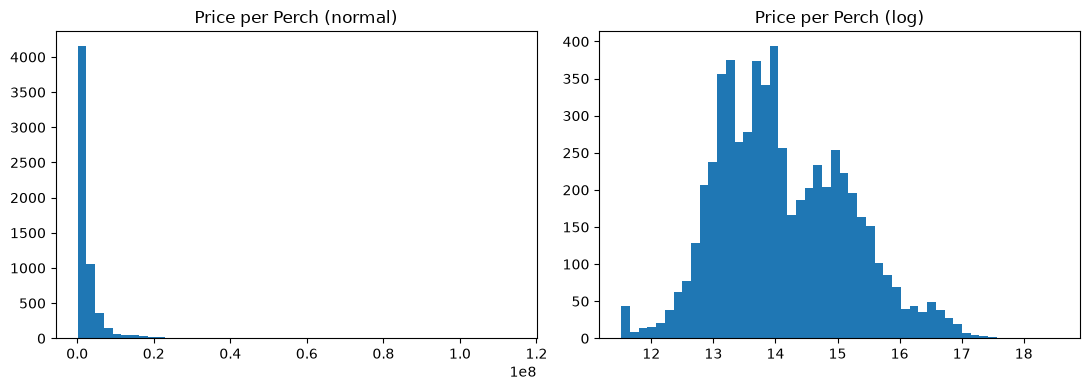

In [4]:
# Summary numbers of the target column
print(land["Price per Perch"].describe())

# Plot the price: normal scale and log scale side by side
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(land["Price per Perch"], bins=50)
ax[0].set_title("Price per Perch (normal)")

ax[1].hist(np.log(land["Price per Perch"]), bins=50)
ax[1].set_title("Price per Perch (log)")

plt.tight_layout()
plt.show()
